In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 42
EPOCHS = 5
BATCH_SIZE = 64
LEARNING_RATE = 0.001

# Set False to use the full training/validation/test datasets.
QUICK_RUN = True

tf.keras.utils.set_random_seed(SEED)

OUTPUT = Path("cnn_portfolio_results")
OUTPUT.mkdir(exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.22.0-rc0
GPUs: []


In [3]:
(X_full, y_full), (X_test_full, y_test_full) = (
    tf.keras.datasets.cifar10.load_data()
)

y_full = y_full.ravel()
y_test_full = y_test_full.ravel()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Fixed, stratified training/validation split.
train_ids, val_ids = train_test_split(
    np.arange(len(X_full)),
    test_size=0.2,
    random_state=SEED,
    stratify=y_full
)

test_ids = np.arange(len(X_test_full))

if QUICK_RUN:
    train_ids, _ = train_test_split(
        train_ids,
        train_size=5000,
        random_state=SEED,
        stratify=y_full[train_ids]
    )

    val_ids, _ = train_test_split(
        val_ids,
        train_size=1000,
        random_state=SEED,
        stratify=y_full[val_ids]
    )

    test_ids, _ = train_test_split(
        test_ids,
        train_size=1000,
        random_state=SEED,
        stratify=y_test_full
    )

X_train = X_full[train_ids].astype("float32") / 255.0
y_train = y_full[train_ids]

X_val = X_full[val_ids].astype("float32") / 255.0
y_val = y_full[val_ids]

X_test = X_test_full[test_ids].astype("float32") / 255.0
y_test = y_test_full[test_ids]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# Free the unused full image arrays.
del X_full, X_test_full

Training: (5000, 32, 32, 3)
Validation: (1000, 32, 32, 3)
Testing: (1000, 32, 32, 3)


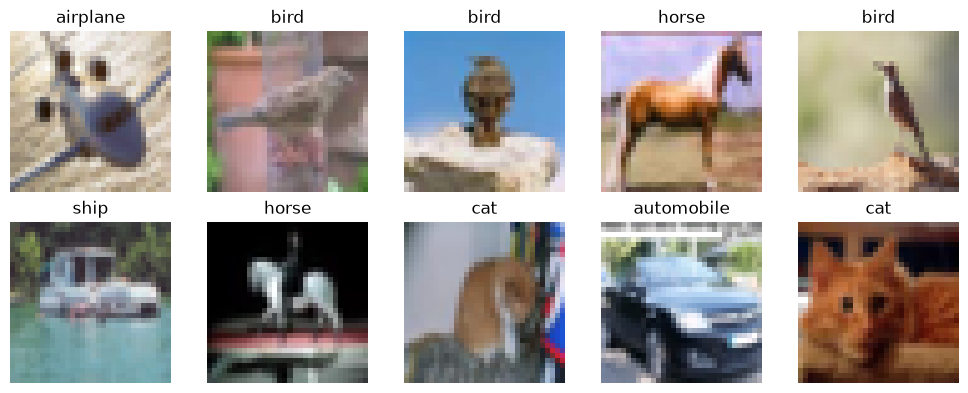

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i])
    ax.set_title(class_names[y_train[i]])
    ax.axis("off")

fig.tight_layout()
fig.savefig(OUTPUT / "dataset_examples.png", dpi=180)
plt.show()

In [5]:
def build_model(use_pooling):
    inputs = layers.Input(shape=(32, 32, 3), name="image")

    x = layers.Conv2D(
        16,
        kernel_size=3,
        padding="same",
        activation="relu",
        name="conv1"
    )(inputs)

    if use_pooling:
        x = layers.MaxPooling2D(
            pool_size=2,
            name="pool1"
        )(x)

    x = layers.Conv2D(
        32,
        kernel_size=3,
        padding="same",
        activation="relu",
        name="last_conv"
    )(x)

    if use_pooling:
        x = layers.MaxPooling2D(
            pool_size=2,
            name="pool2"
        )(x)

    x = layers.Flatten(name="flatten")(x)

    outputs = layers.Dense(
        10,
        name="class_scores"
    )(x)

    model = Model(
        inputs,
        outputs,
        name="cnn_pooling" if use_pooling else "cnn_no_pooling"
    )

    # Each model gets its own fresh optimizer.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            )
        ]
    )

    return model


tf.keras.utils.set_random_seed(SEED)
model_pooling = build_model(use_pooling=True)

tf.keras.utils.set_random_seed(SEED)
model_no_pooling = build_model(use_pooling=False)

models = {
    "With pooling": model_pooling,
    "Without pooling": model_no_pooling
}

In [6]:
for name, model in models.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    model.summary()

    summary_lines = []

    model.summary(
        print_fn=lambda line, **kwargs: summary_lines.append(line)
    )

    filename = name.lower().replace(" ", "_") + "_summary.txt"

    (OUTPUT / filename).write_text(
        "\n".join(summary_lines),
        encoding="utf-8"
    )


With pooling


Model: "cnn_pooling"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_scores (Dense)            │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,578 (99.91 KB)

 Trainable params: 25,578 (99.91 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_scores (Dense)            │ (None, 10)             │       327,690 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 332,778 (1.27 MB)

 Trainable params: 332,778 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
def make_training_dataset():
    return (
        tf.data.Dataset
        .from_tensor_slices((X_train, y_train))
        .shuffle(
            buffer_size=len(X_train),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )


validation_dataset = (
    tf.data.Dataset
    .from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

histories = {}
training_times = {}

for name, model in models.items():
    print(f"\nTraining: {name}")

    tf.keras.utils.set_random_seed(SEED)
    train_dataset = make_training_dataset()

    start = time.perf_counter()

    history = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=EPOCHS,
        verbose=1
    )

    training_times[name] = time.perf_counter() - start
    histories[name] = history.history

    print(
        f"{name} training time: "
        f"{training_times[name]:.2f} seconds"
    )


Training: With pooling
Epoch 1/5


c:\Users\User\CN6005 Portfolio\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.2538 - loss: 2.0891 - val_accuracy: 0.3440 - val_loss: 1.8288
Epoch 2/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.3984 - loss: 1.7229 - val_accuracy: 0.3900 - val_loss: 1.6950
Epoch 3/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.4332 - loss: 1.6020 - val_accuracy: 0.4280 - val_loss: 1.5756
Epoch 4/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.4808 - loss: 1.4957 - val_accuracy: 0.4480 - val_loss: 1.5283
Epoch 5/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.4974 - loss: 1.4290 - val_accuracy: 0.4570 - val_loss: 1.5077
With pooling training time: 22.82 seconds

Training: Without pooling
Epoch 1/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - accuracy: 0.3044 - loss: 1.9438 - val_accuracy: 0.4090 - val_loss: 1.6741
Epoch 2/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.4902 - loss: 1.4817 - val_accuracy: 0.4370 - val_loss: 1.5639
Epoch 3/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accurac

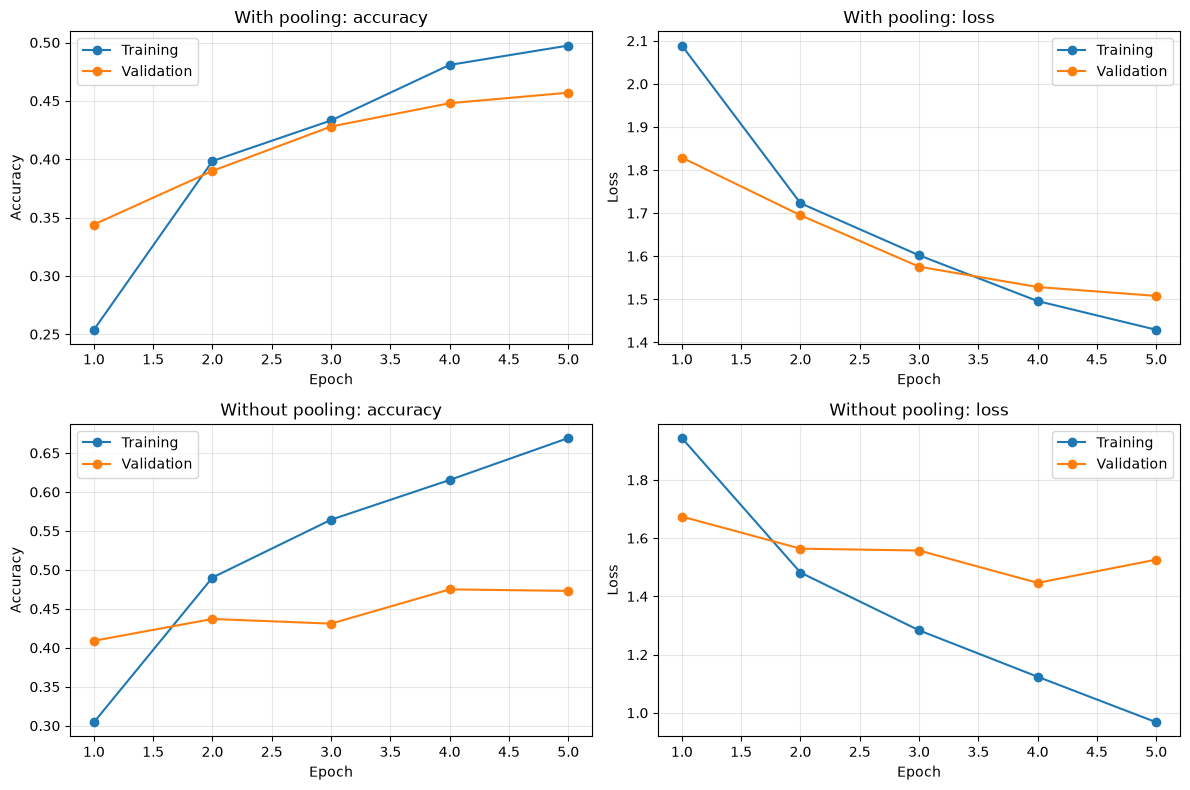

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, name in enumerate(models):
    history = histories[name]
    epochs = range(1, len(history["accuracy"]) + 1)

    axes[row, 0].plot(
        epochs,
        history["accuracy"],
        marker="o",
        label="Training"
    )

    axes[row, 0].plot(
        epochs,
        history["val_accuracy"],
        marker="o",
        label="Validation"
    )

    axes[row, 0].set(
        title=f"{name}: accuracy",
        xlabel="Epoch",
        ylabel="Accuracy"
    )

    axes[row, 0].legend()
    axes[row, 0].grid(alpha=0.3)

    axes[row, 1].plot(
        epochs,
        history["loss"],
        marker="o",
        label="Training"
    )

    axes[row, 1].plot(
        epochs,
        history["val_loss"],
        marker="o",
        label="Validation"
    )

    axes[row, 1].set(
        title=f"{name}: loss",
        xlabel="Epoch",
        ylabel="Loss"
    )

    axes[row, 1].legend()
    axes[row, 1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUTPUT / "accuracy_loss_graphs.png", dpi=180)
plt.show()

,Model,Parameters,Training accuracy (%),Validation accuracy (%),Test accuracy (%),Test loss,Training time (s)
0,With pooling,25578,49.74,45.7,47.7,1.47,22.82
1,Without pooling,332778,66.92,47.3,48.7,1.51,20.24


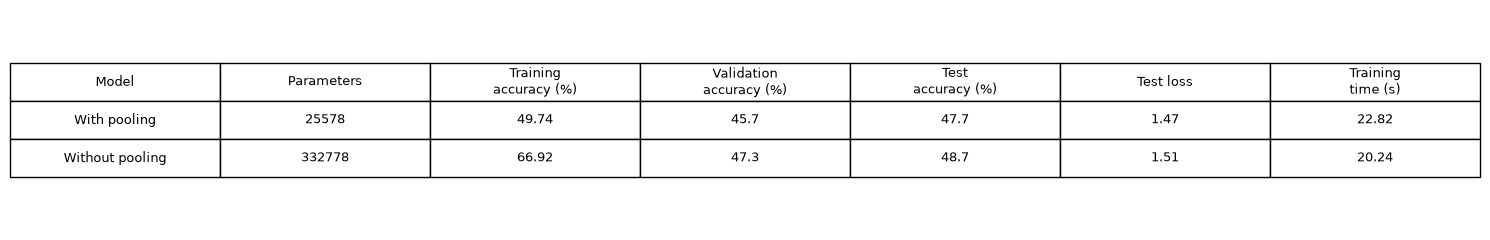

Highest observed test accuracy: Without pooling
Test accuracy: 48.70%


In [9]:
results = []

for name, model in models.items():
    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    history = histories[name]

    results.append({
        "Model": name,
        "Parameters": model.count_params(),
        "Training accuracy (%)": history["accuracy"][-1] * 100,
        "Validation accuracy (%)": history["val_accuracy"][-1] * 100,
        "Test accuracy (%)": test_accuracy * 100,
        "Test loss": test_loss,
        "Training time (s)": training_times[name]
    })

comparison = pd.DataFrame(results)

display(comparison.round(2))

comparison.to_csv(
    OUTPUT / "model_comparison.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(15, 2.5))
ax.axis("off")

table = ax.table(
    cellText=comparison.round(2).astype(str).values,
    colLabels=[
        "Model",
        "Parameters",
        "Training\naccuracy (%)",
        "Validation\naccuracy (%)",
        "Test\naccuracy (%)",
        "Test loss",
        "Training\ntime (s)"
    ],
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2)

fig.tight_layout()
fig.savefig(
    OUTPUT / "model_comparison.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

best_row = comparison.loc[
    comparison["Test accuracy (%)"].idxmax()
]

print("Highest observed test accuracy:", best_row["Model"])
print(f"Test accuracy: {best_row['Test accuracy (%)']:.2f}%")

In [10]:
def make_gradcam_heatmap(
    image,
    model,
    layer_name="last_conv"
):
    gradient_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(layer_name).output,
            model.output
        ]
    )

    image_batch = tf.convert_to_tensor(
        image[np.newaxis, ...],
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:
        feature_maps, scores = gradient_model(
            image_batch,
            training=False
        )

        predicted_class = tf.argmax(
            scores[0],
            output_type=tf.int32
        )

        class_score = tf.gather(
            scores[0],
            predicted_class
        )

    gradients = tape.gradient(
        class_score,
        feature_maps
    )

    if gradients is None:
        raise RuntimeError(
            "Could not calculate Grad-CAM gradients."
        )

    channel_weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    heatmap = tf.reduce_sum(
        feature_maps[0] * channel_weights,
        axis=-1
    )

    # Retain positive contributions.
    heatmap = tf.maximum(heatmap, 0)

    # Safely normalise, including all-zero heatmaps.
    heatmap = tf.math.divide_no_nan(
        heatmap,
        tf.reduce_max(heatmap)
    )

    probabilities = tf.nn.softmax(scores[0])

    return (
        heatmap.numpy(),
        int(predicted_class.numpy()),
        float(tf.reduce_max(probabilities).numpy())
    )

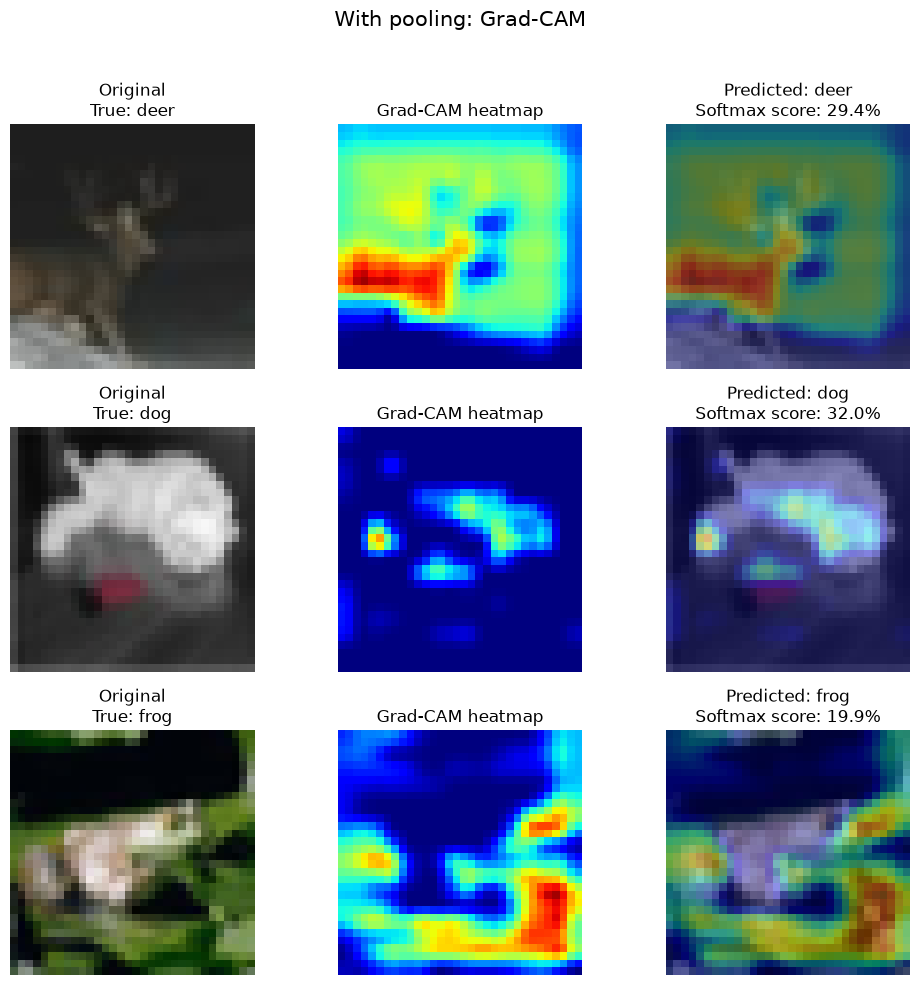

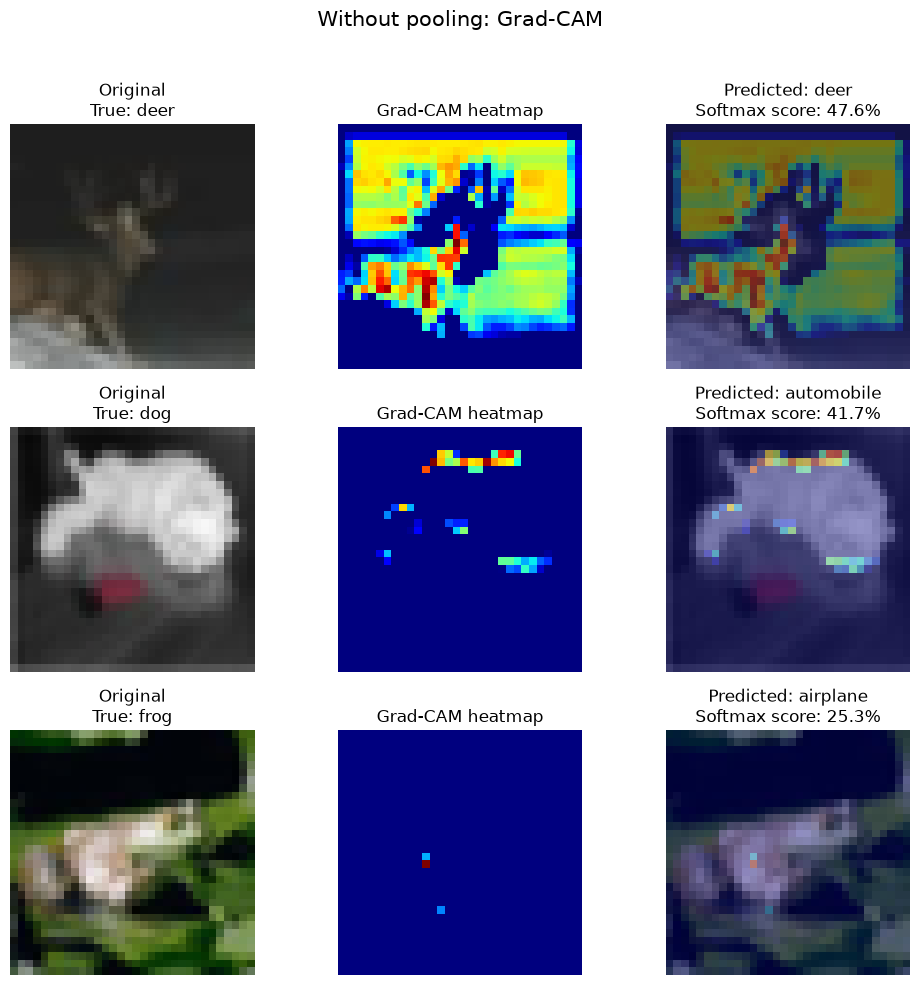

,Model,Test subset index,Original test index,True class,Predicted class,Softmax score,Correct
0,With pooling,0,9128,deer,deer,0.294,True
1,With pooling,1,5468,dog,dog,0.320,True
2,With pooling,2,62,frog,frog,0.199,True
3,Without pooling,0,9128,deer,deer,0.476,True
4,Without pooling,1,5468,dog,automobile,0.417,False
5,Without pooling,2,62,frog,airplane,0.253,False


In [11]:
# Fixed examples; do not select only successful predictions.
sample_indices = [0, 1, 2]

prediction_rows = []

for name, model in models.items():
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))

    for row, index in enumerate(sample_indices):
        image = X_test[index]
        true_class = int(y_test[index])

        heatmap, predicted_class, confidence = (
            make_gradcam_heatmap(image, model)
        )

        resized_heatmap = tf.image.resize(
            heatmap[..., np.newaxis],
            size=image.shape[:2]
        ).numpy().squeeze()

        coloured_heatmap = plt.get_cmap("jet")(
            resized_heatmap
        )[..., :3]

        overlay = np.clip(
            0.6 * image + 0.4 * coloured_heatmap,
            0,
            1
        )

        axes[row, 0].imshow(image)
        axes[row, 0].set_title(
            f"Original\nTrue: {class_names[true_class]}"
        )

        axes[row, 1].imshow(
            resized_heatmap,
            cmap="jet",
            vmin=0,
            vmax=1
        )
        axes[row, 1].set_title("Grad-CAM heatmap")

        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title(
            f"Predicted: {class_names[predicted_class]}\n"
            f"Softmax score: {confidence:.1%}"
        )

        for ax in axes[row]:
            ax.axis("off")

        prediction_rows.append({
            "Model": name,
            "Test subset index": index,
            "Original test index": int(test_ids[index]),
            "True class": class_names[true_class],
            "Predicted class": class_names[predicted_class],
            "Softmax score": confidence,
            "Correct": predicted_class == true_class
        })

    fig.suptitle(f"{name}: Grad-CAM", fontsize=15)
    fig.tight_layout(rect=[0, 0, 1, 0.96])

    filename = (
        name.lower().replace(" ", "_") + "_gradcam.png"
    )

    fig.savefig(
        OUTPUT / filename,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

prediction_table = pd.DataFrame(prediction_rows)

display(prediction_table.round(3))

prediction_table.to_csv(
    OUTPUT / "sample_predictions.csv",
    index=False
)

In [12]:
for name, model in models.items():
    filename = name.lower().replace(" ", "_")

    model.save(OUTPUT / f"{filename}.keras")

    pd.DataFrame(histories[name]).to_csv(
        OUTPUT / f"{filename}_history.csv",
        index=False
    )

settings = pd.DataFrame([{
    "Seed": SEED,
    "Epochs": EPOCHS,
    "Batch size": BATCH_SIZE,
    "Optimizer": "Adam",
    "Learning rate": LEARNING_RATE,
    "Training images": len(X_train),
    "Validation images": len(X_val),
    "Test images": len(X_test),
    "Quick run": QUICK_RUN
}])

settings.to_csv(
    OUTPUT / "experiment_settings.csv",
    index=False
)

print("All results saved in:")
print(OUTPUT.resolve())

All results saved in:
C:\Users\User\CN6005 Portfolio\Week 4\cnn_portfolio_results
